In [78]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import pandas as pd
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Scikit-learn Modelleri
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

In [79]:
iris = load_iris()
iris.feature_names
a=iris.DESCR

X_full = iris.data
y_full = iris.target
print(a)


.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

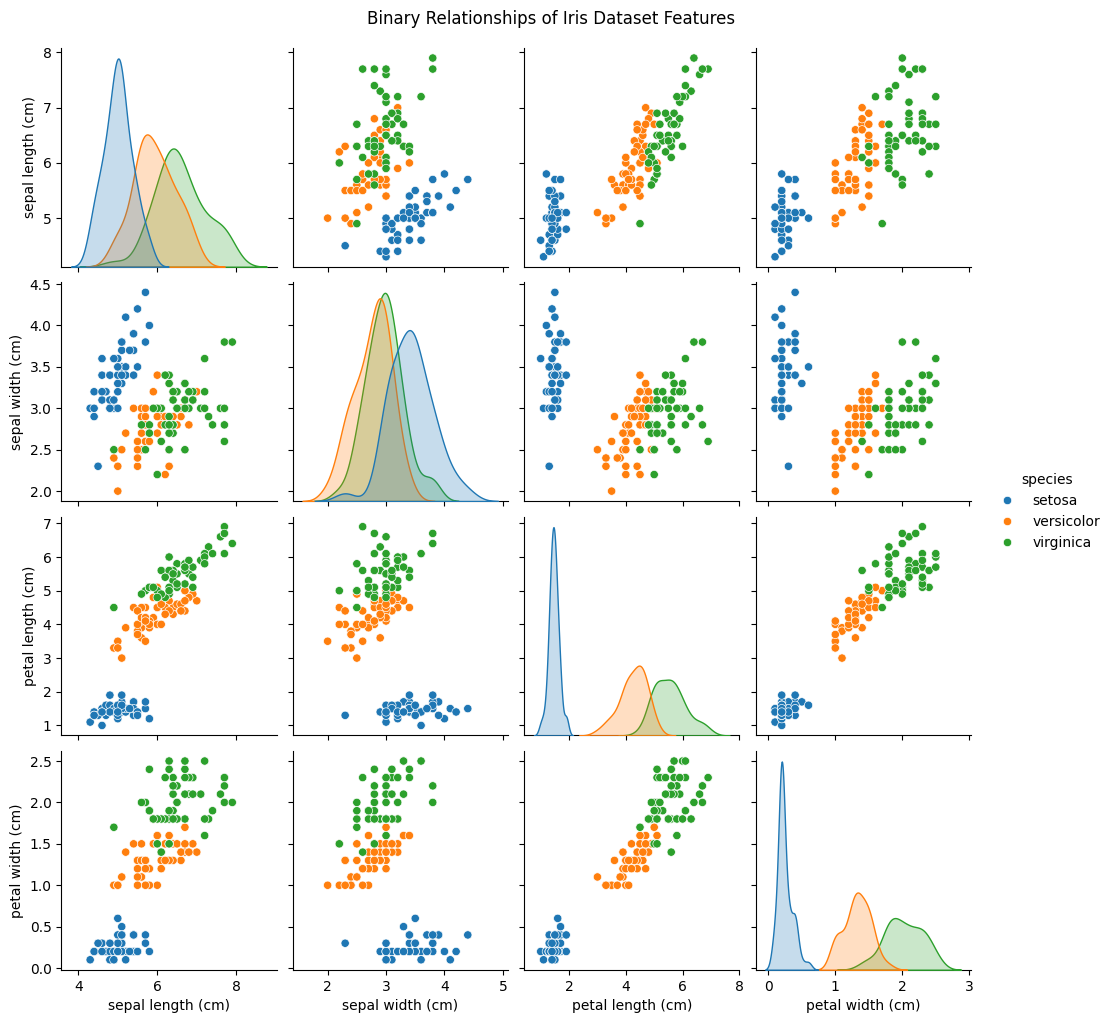

In [80]:
df_full_iris = pd.DataFrame(data=X_full, columns=iris.feature_names)
df_full_iris['species'] = iris.target_names[y_full]
sns.pairplot(df_full_iris, hue='species', diag_kind='kde')
plt.suptitle('Binary Relationships of Iris Dataset Features', y=1.02)
plt.show()

In [81]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [82]:
X_full = iris.data
y_full = iris.target

# 4 Feature raw data train-test split
X_train_full, X_test_full, y_train, y_test = train_test_split(X_full, y_full, 
                                                              test_size=0.3, 
                                                              random_state=42, 
                                                              stratify=y_full)

X_train_2f = X_train_full[:, [2, 3]]
X_test_2f = X_test_full[:, [2, 3]]

X_full.shape




(150, 4)

In [83]:
scaler_2f = StandardScaler()
# Only fit on training data
X_train_2f_scaled = scaler_2f.fit_transform(X_train_2f)

# Transform test data with the fitted scaler
X_test_2f_scaled = scaler_2f.transform(X_test_2f)


# Full feature set scaling
scaler_full = StandardScaler()
X_train_scaled = scaler_full.fit_transform(X_train_full)
X_test_scaled = scaler_full.transform(X_test_full)

In [84]:
def plot_decision_boundary(X, y, model, title):
    """
    Visualize the decision boundaries of a classifier.
    """
    # Set color maps and markers
    cmap_light = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF'])
    cmap_bold = ['red', 'green', 'blue']

    # Set step size
    h = .02  # step size in the mesh

    # Find the min and max values of the features and leave some margin
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Create a mesh grid
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # Make predictions for each point in the grid
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

    # Reshape the result back to the grid shape
    Z = Z.reshape(xx.shape)

    # Plot the graph
    plt.figure(figsize=(10, 8))
    # Color the decision boundaries
    plt.contourf(xx, yy, Z, cmap=cmap_light)

    # Draw the training points on top
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=iris.target_names[y],
                    palette=cmap_bold, alpha=1.0, edgecolor="black")
    
    plt.xlim(xx.min(), xx.max())
    plt.ylim(yy.min(), yy.max())
    plt.title(title)
    plt.xlabel('Petal Length (cm)')
    plt.ylabel('Petal Width (cm)')
    plt.legend(title='Species')
    plt.show()



In [85]:
class SingleLayerPerceptron:
    """Single Layer Perceptron (SLP) classifier."""
    def __init__(self, learning_rate=0.01, n_iters=1000, random_state=42):
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.random_state = random_state
        self.weights_ = None
        self.errors_ = []
        #Weights initialization moved to fit method.

   

    def fit(self, X, y, plot_every=None): #plot_every may be called from OvR
        """Fits the model to the training data."""
        
        
        rgen = np.random.RandomState(self.random_state)
        # init weights according to X shape
        if self.weights_ is None: 
            self.weights_ = rgen.normal(loc=0.0, scale=0.01, size=X.shape[1] + 1) 
        # --------------------------------------------------------

        self.errors_ = []
        for epoch in range(self.n_iters):
            self.train_epoch(X, y) 
            
        return self

    # train_epoch method
    def train_epoch(self, X, y):
        """One epoch of training."""
        X_b = np.c_[np.ones((len(X), 1)), X]
        errors = 0
        for xi, target in zip(X_b, y):
            # predict(xi) calls net_input(xi), which calls np.dot(xi, self.weights_)
            # now self.weights_ should be of correct shape (3,)
            update = self.learning_rate * (target - self.predict(xi)) 
            self.weights_ += update * xi
            errors += int(update != 0.0)
        self.errors_.append(errors)
        
    # net_input method
    def net_input(self, X):
        """Calculates net input."""
        if X.ndim == 2:
             X_b = np.c_[np.ones((len(X), 1)), X]
             # np.dot(X_b [N, 3], self.weights_ [3,])
             return np.dot(X_b, self.weights_)
        else: # Single sample (xi, shape is (3,))
             # np.dot(X [3,], self.weights_ [3,]) 
             return np.dot(X, self.weights_)

    # predict method
    def predict(self, X):
        """Makes a prediction (unit step function)."""
        return np.where(self.net_input(X) >= 0.0, 1, 0)

In [86]:
class SLP_OvR:
    def __init__(self, n_classes, learning_rate=0.01, n_iters=100, random_state=42): # We can set default n_iters lower for OvR
        self.n_classes = n_classes
        self.learning_rate = learning_rate
        self.n_iters = n_iters # iteration count for SLP
        self.random_state = random_state
        self.perceptrons_ = [
            # n_iters for SLP not for OvR
            SingleLayerPerceptron(learning_rate=self.learning_rate, n_iters=1, random_state=self.random_state + i) 
            #every single perceptron gets different seed
            for i in range(self.n_classes)
        ]


    
    def fit(self, X, y, plot_every=5):
        """
        Train each perceptron in a one-vs-rest manner.
        """
        n_features = X.shape[1] # Get number of features

        # Initialize weights to the correct shape from the start (without waiting for SLP.fit)
        for p in self.perceptrons_:
            if p.weights_ is None:
                 rgen = np.random.RandomState(p.random_state)
                 p.weights_ = rgen.normal(loc=0.0, scale=0.01, size=n_features + 1)

        # Epoch
        for epoch in range(self.n_iters): # This for Epoch for OvR
            for i in range(self.n_classes):
                y_ovr = np.where(y == i, 1, 0)
                # Since SLP has n_iters=1 this only runs one epoch
                self.perceptrons_[i].train_epoch(X, y_ovr) 
            
            if (epoch + 1) % plot_every == 0:
                print(f"--- Epoch {epoch + 1} ---")
                plot_decision_boundary(X, y, self,
                                       title=f'SLP Decision Boundaries - Epoch {epoch + 1}')
        return self

    # predict method can remain the same
    def predict(self, X):
        """
        Return the class of the perceptron with the highest activation value as the prediction.
        """
        activations = np.array([p.net_input(X) for p in self.perceptrons_])
        return np.argmax(activations, axis=0)

--- Epoch 5 ---


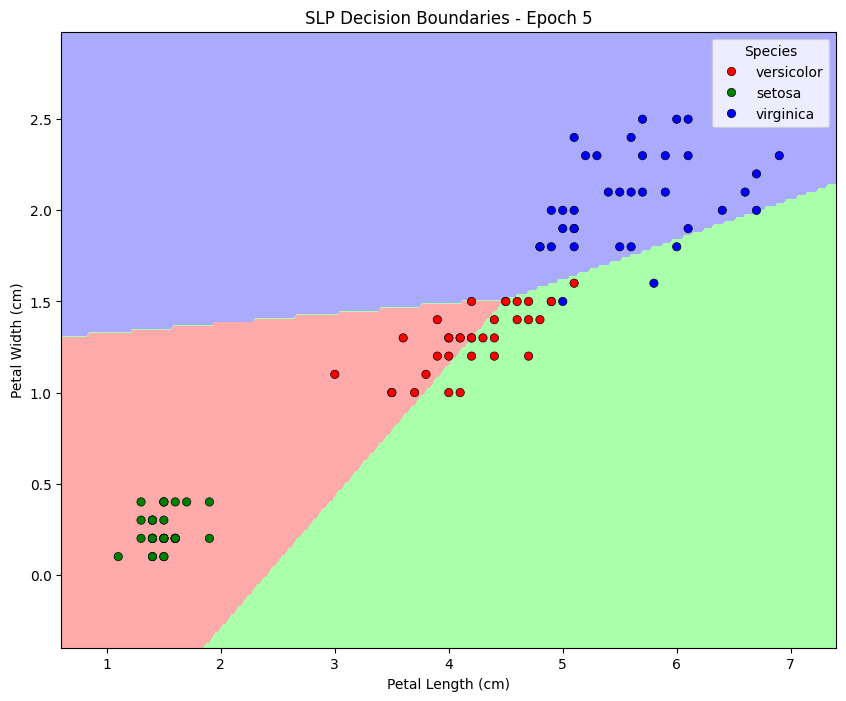

--- Epoch 10 ---


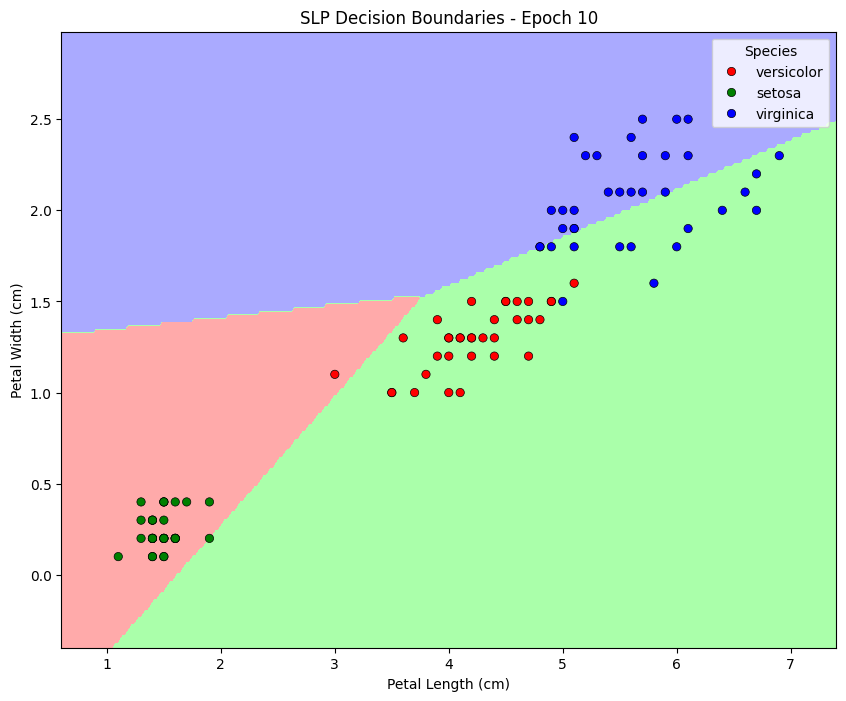

--- Epoch 15 ---


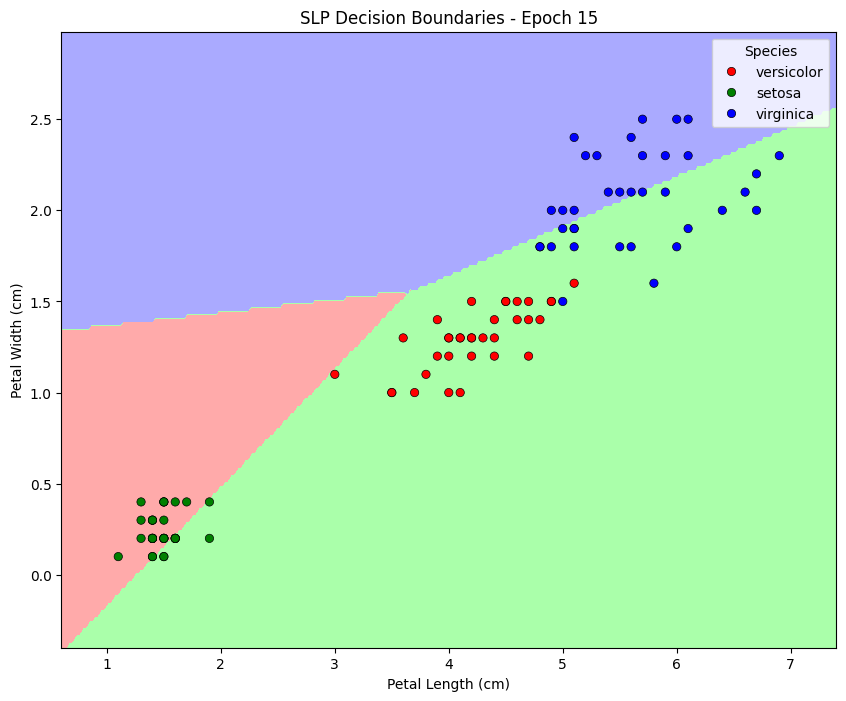

--- Epoch 20 ---


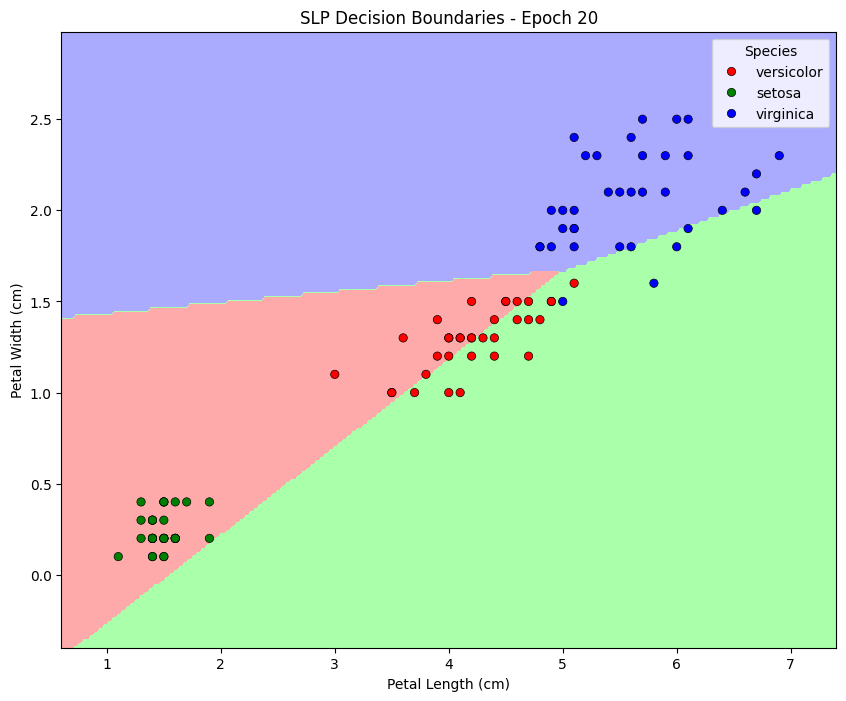

--- Epoch 25 ---


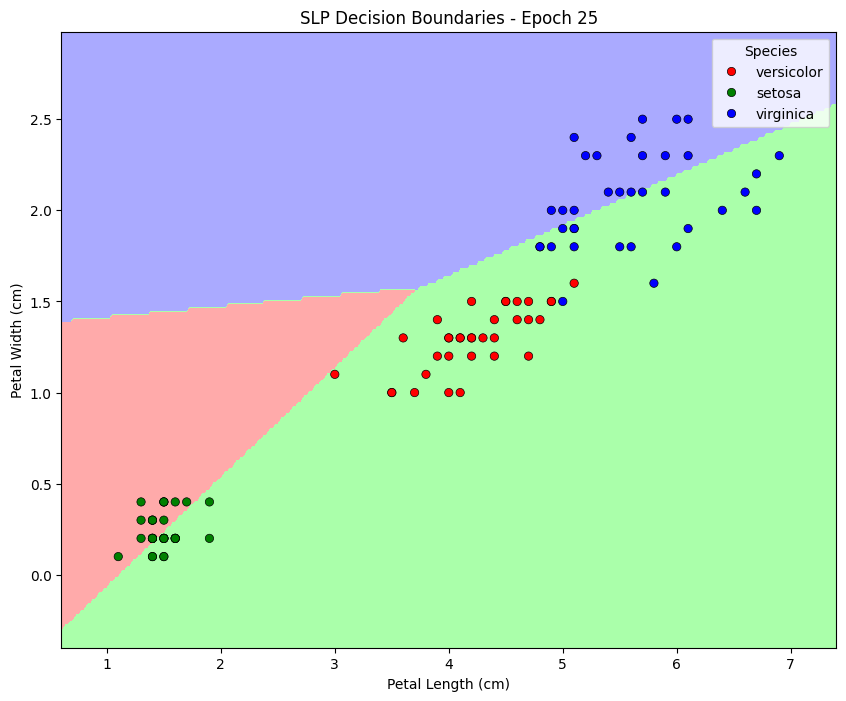

--- Epoch 30 ---


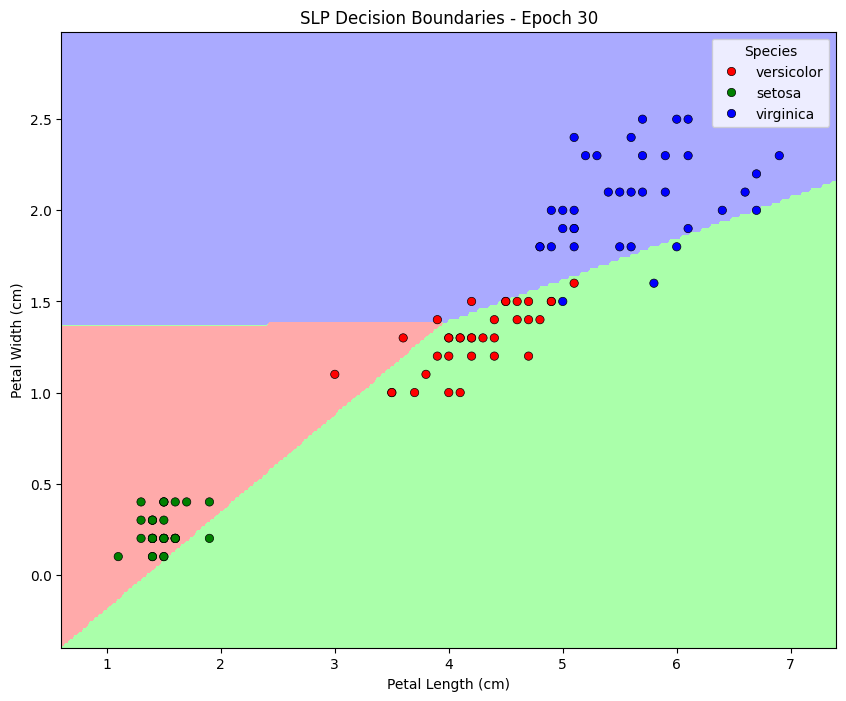

--- Epoch 35 ---


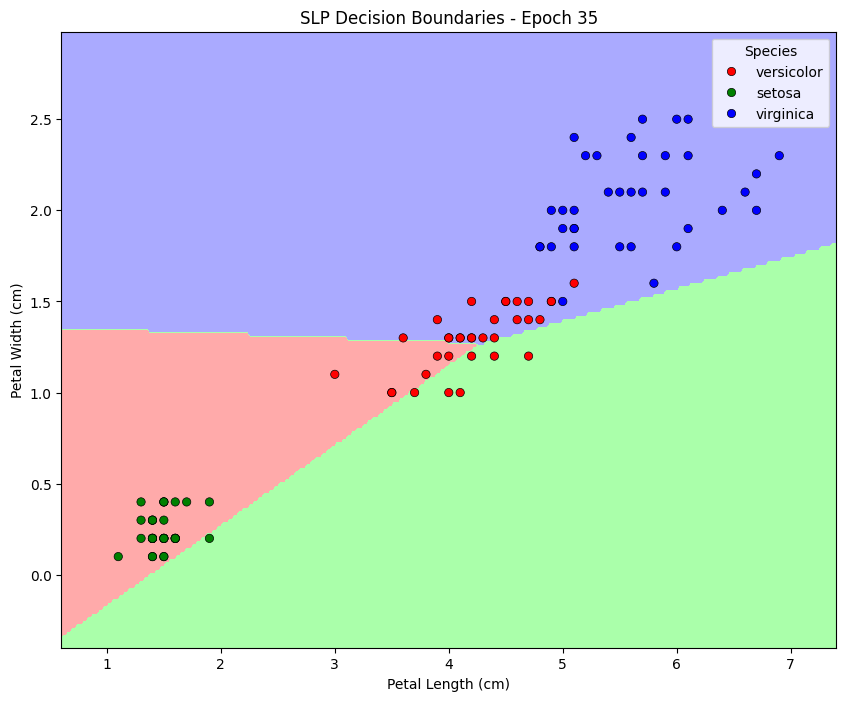

--- Epoch 40 ---


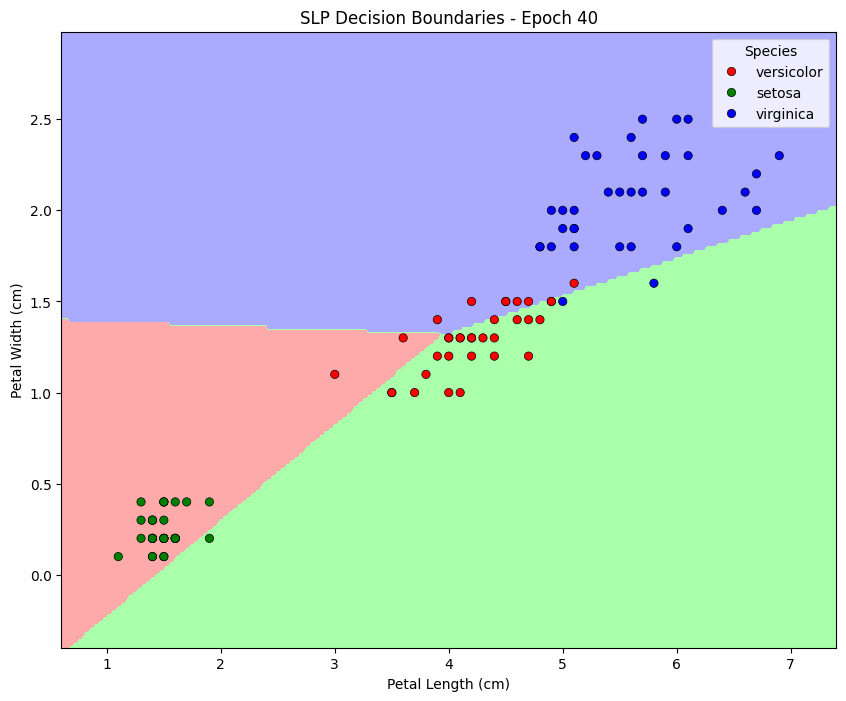

--- Epoch 45 ---


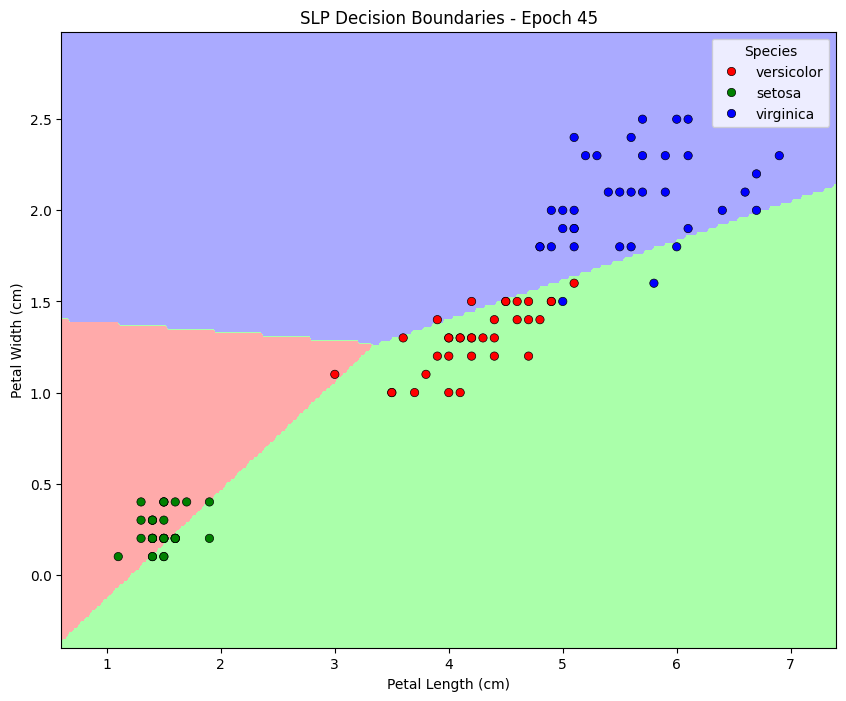

--- Epoch 50 ---


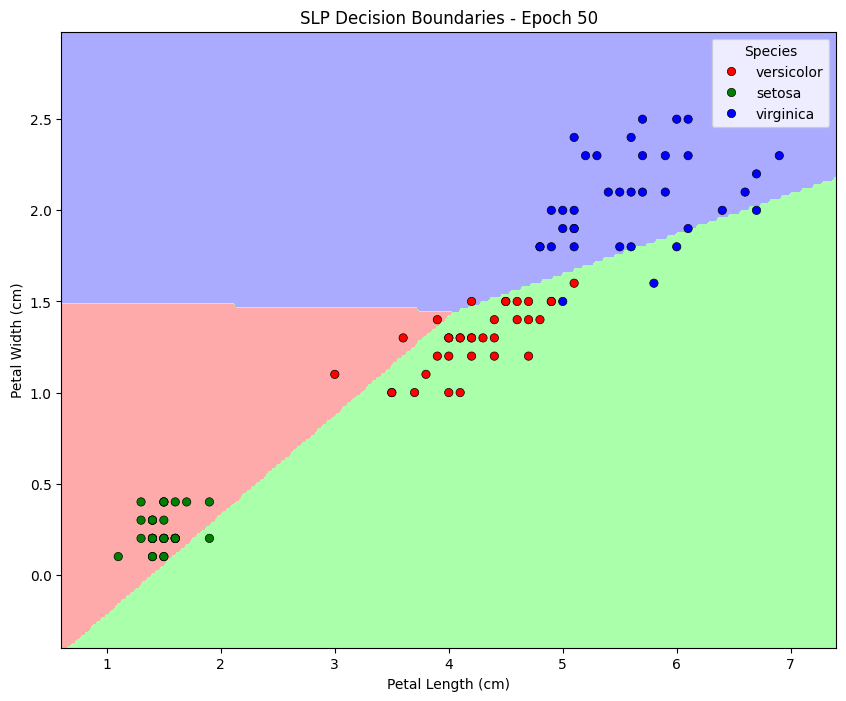

--- Epoch 55 ---


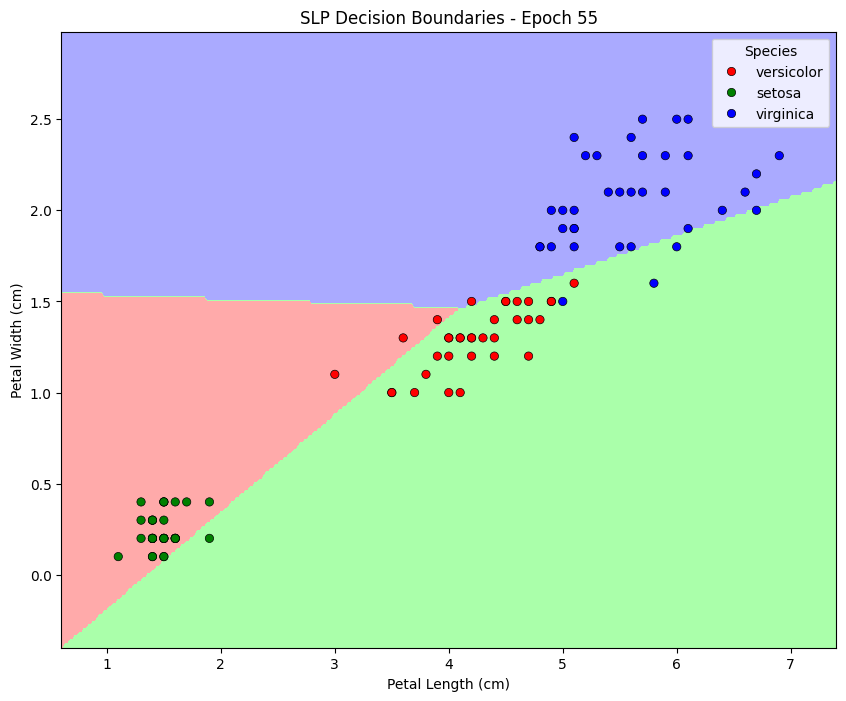

--- Epoch 60 ---


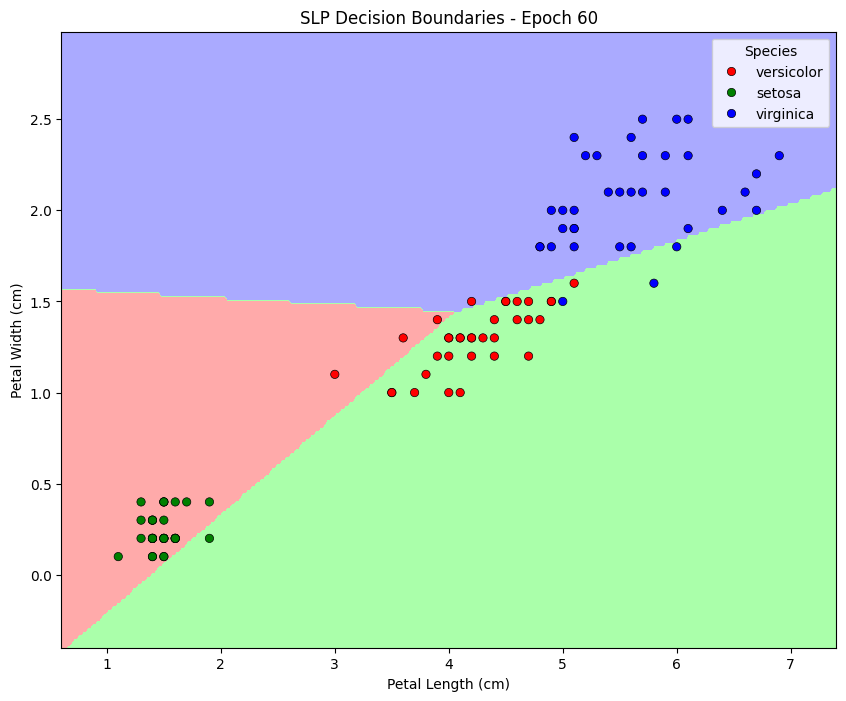

--- Epoch 65 ---


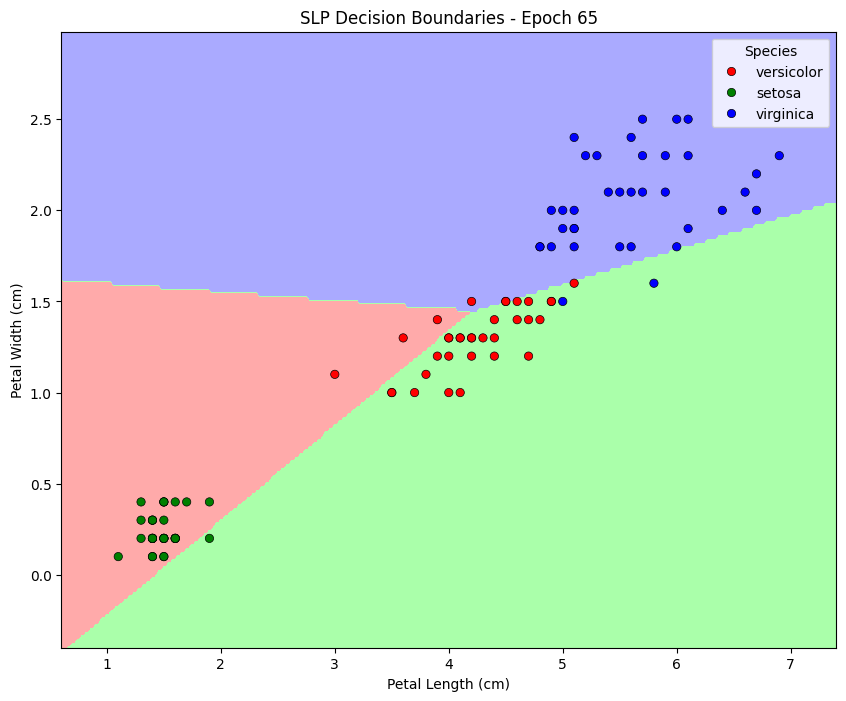

--- Epoch 70 ---


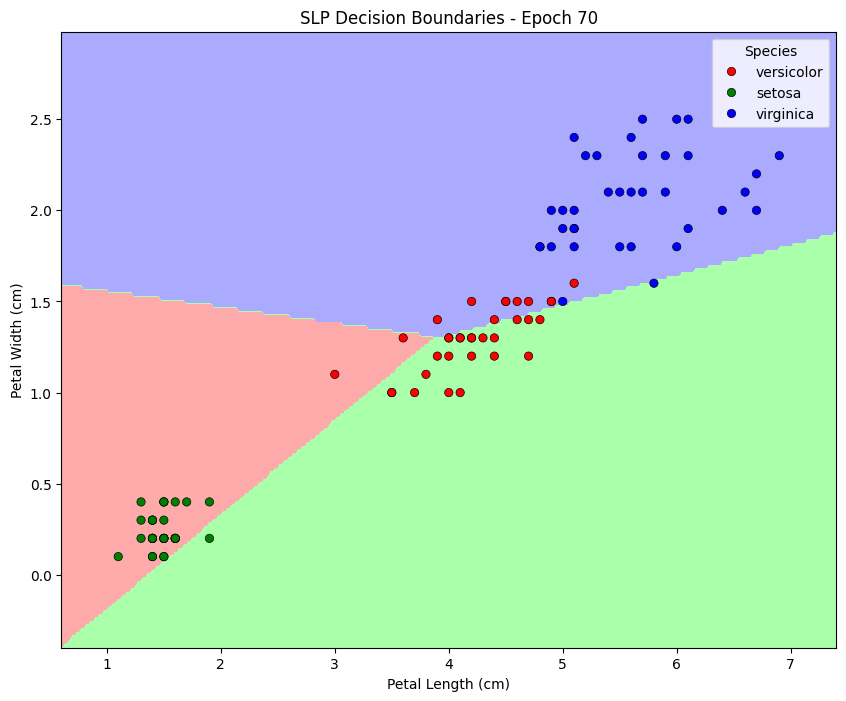

--- Epoch 75 ---


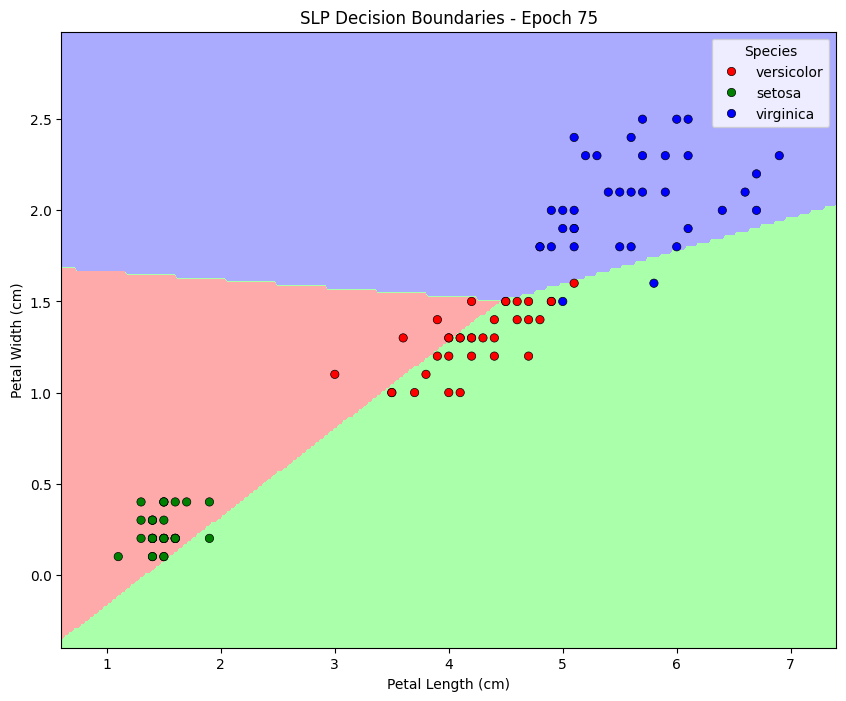

--- Epoch 80 ---


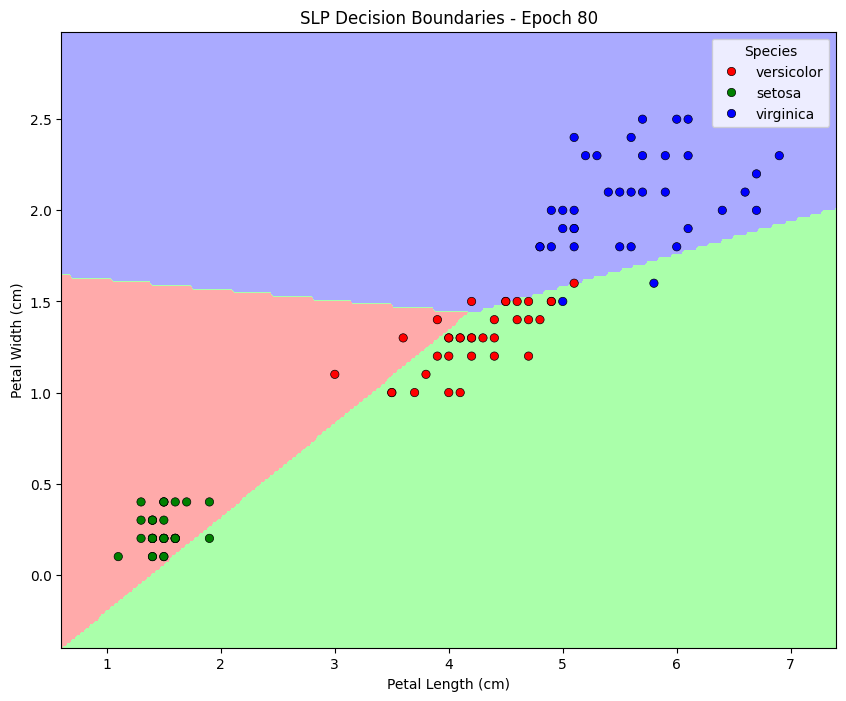

--- Epoch 85 ---


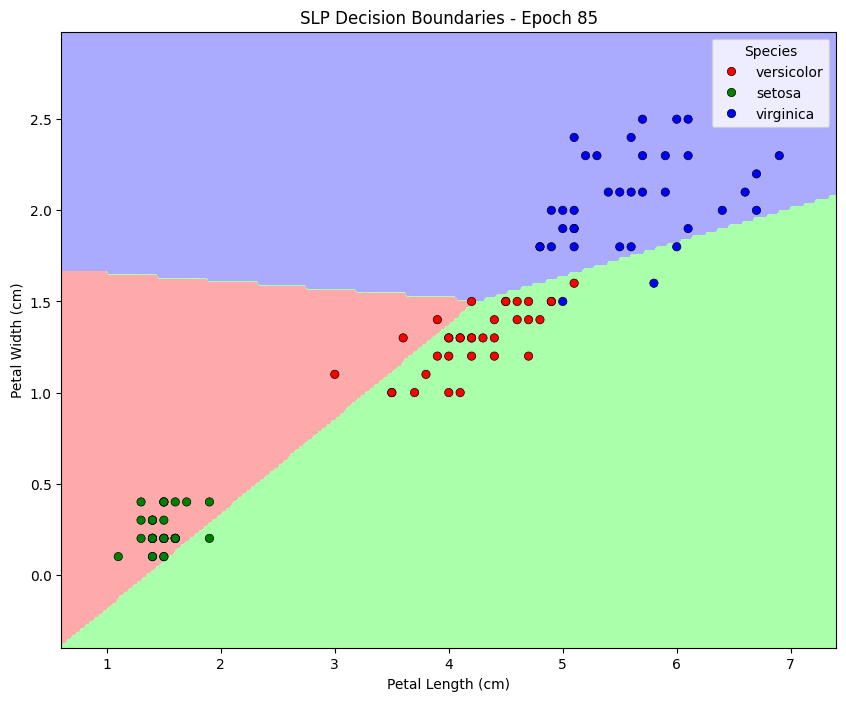

--- Epoch 90 ---


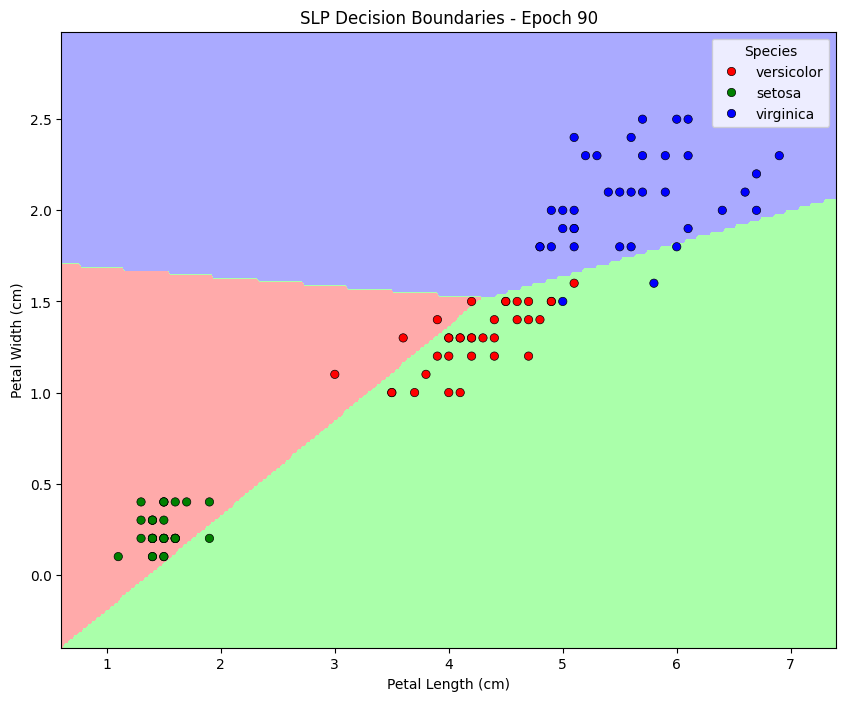

--- Epoch 95 ---


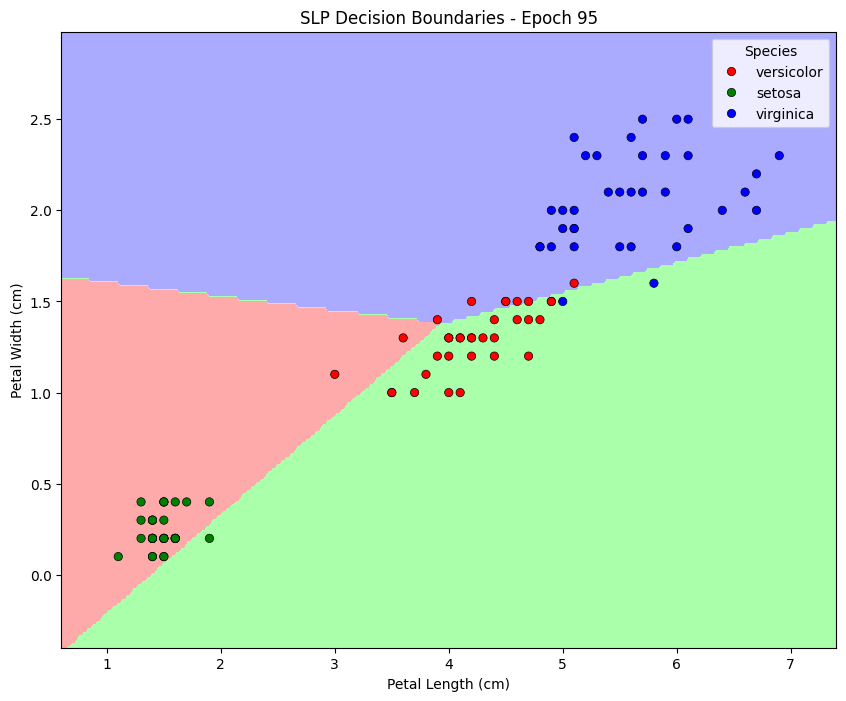

--- Epoch 100 ---


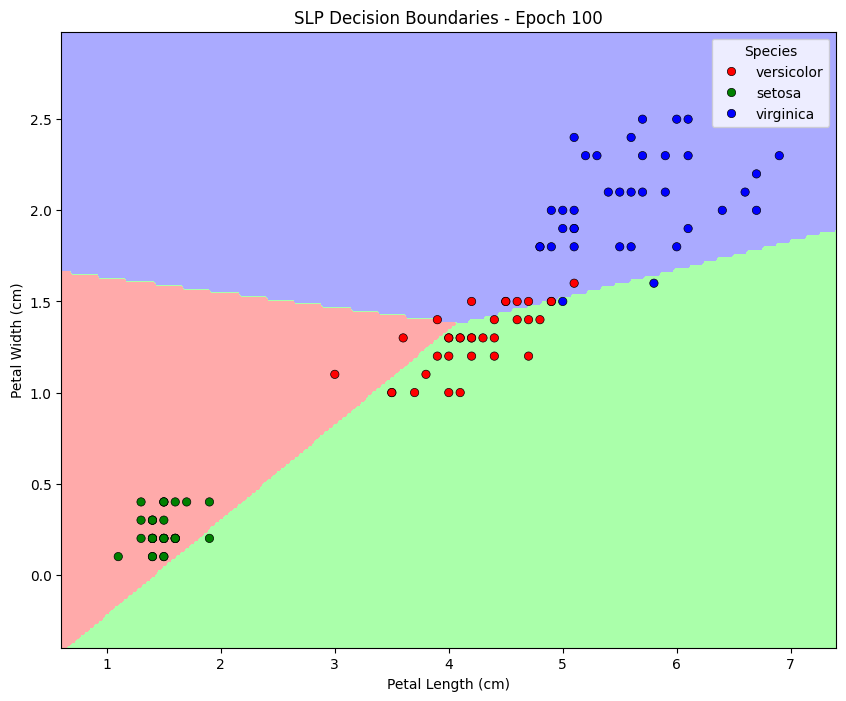

--- Epoch 105 ---


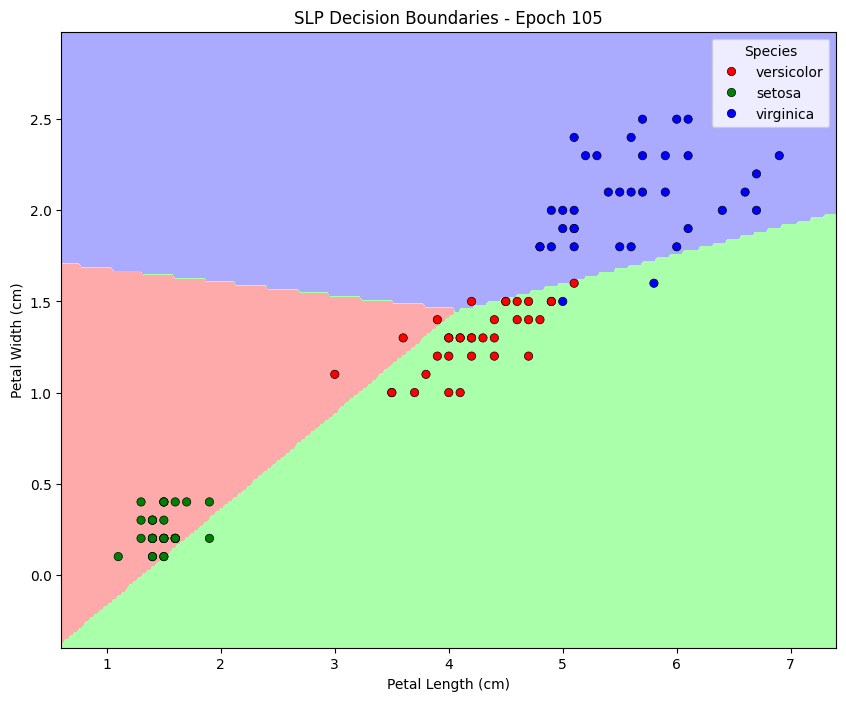

--- Epoch 110 ---


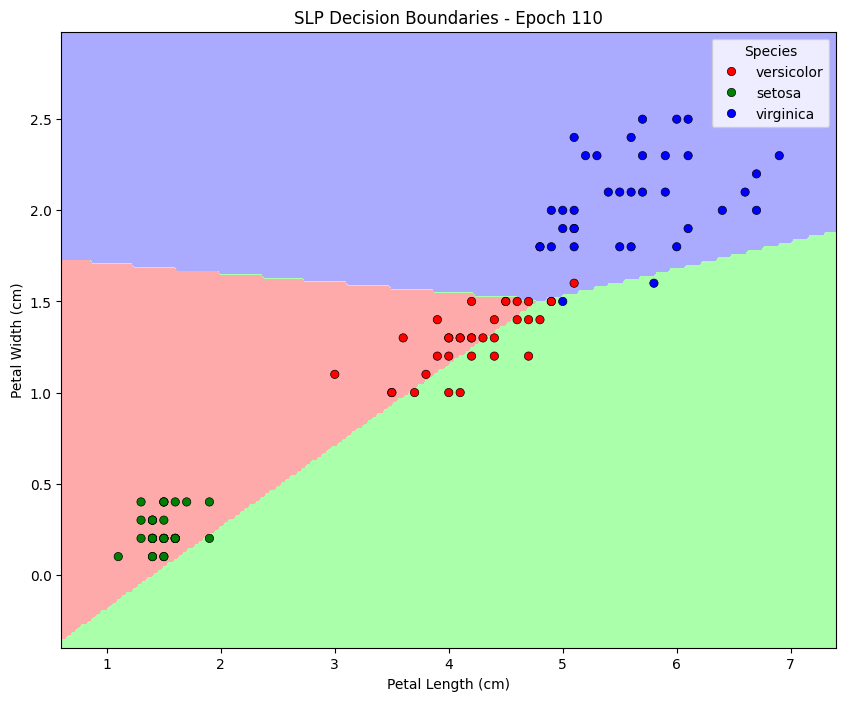

--- Epoch 115 ---


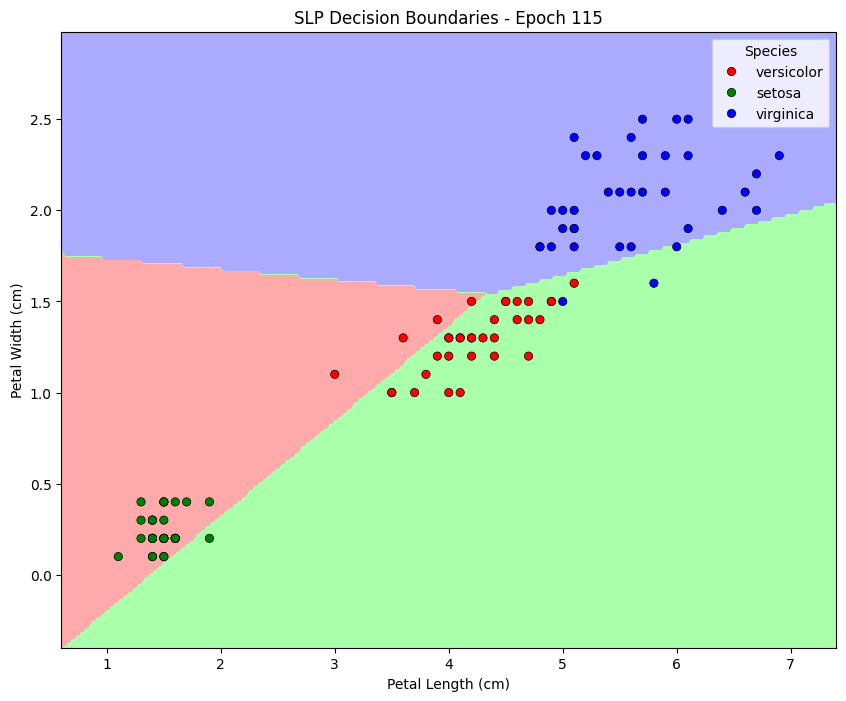

--- Epoch 120 ---


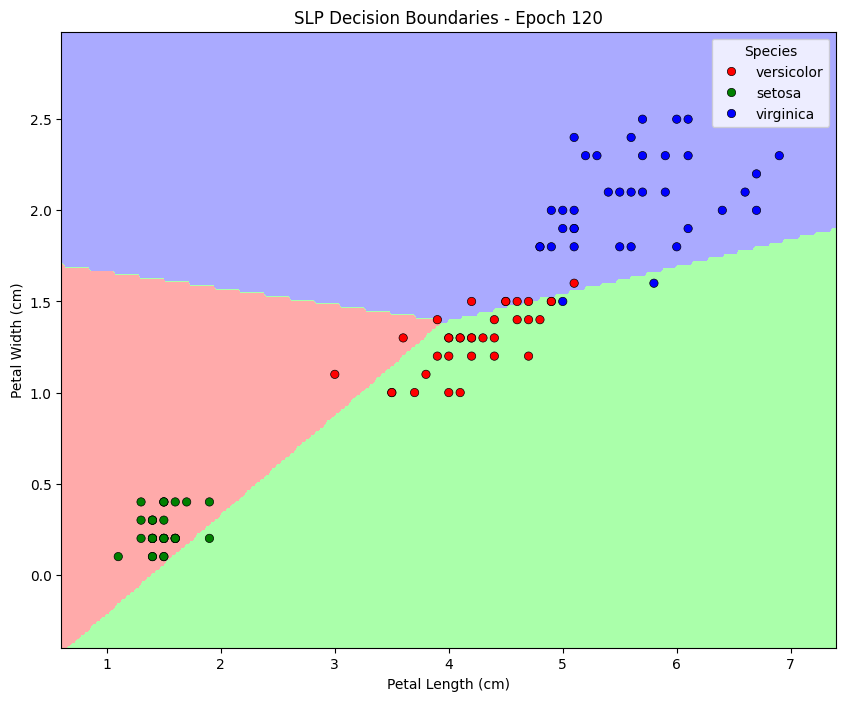

--- Epoch 125 ---


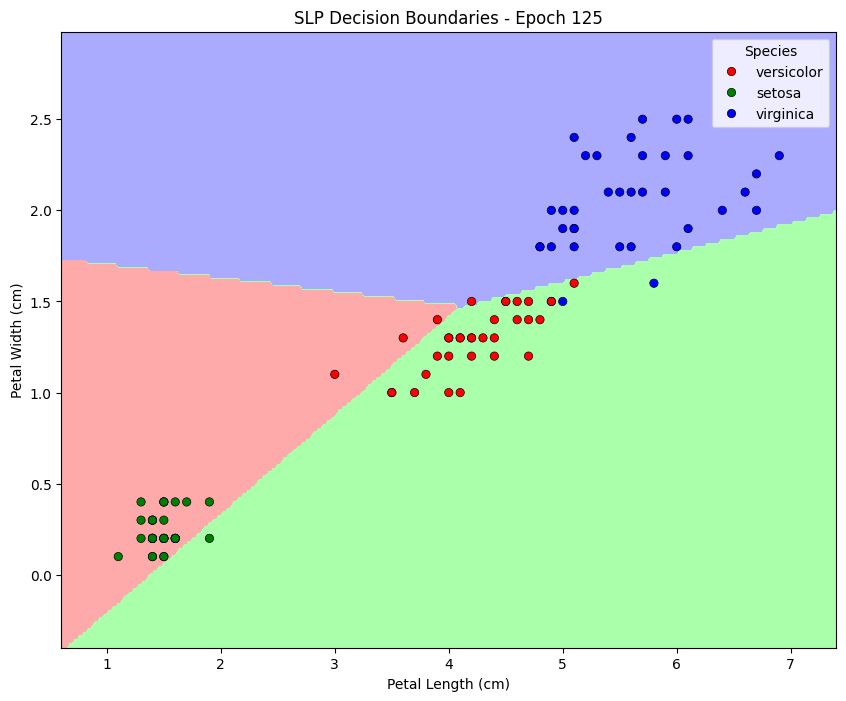

--- Epoch 130 ---


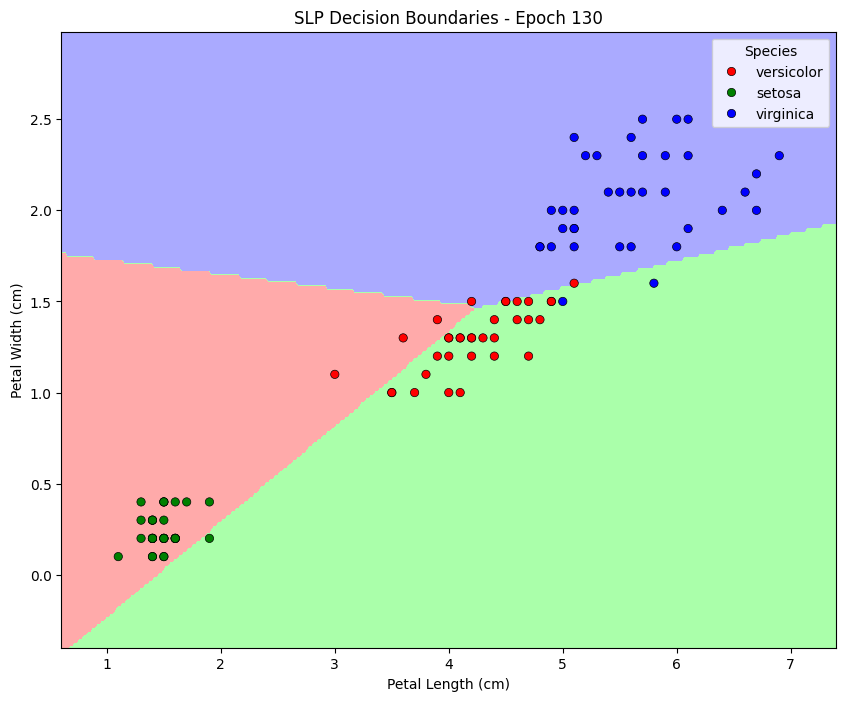

--- Epoch 135 ---


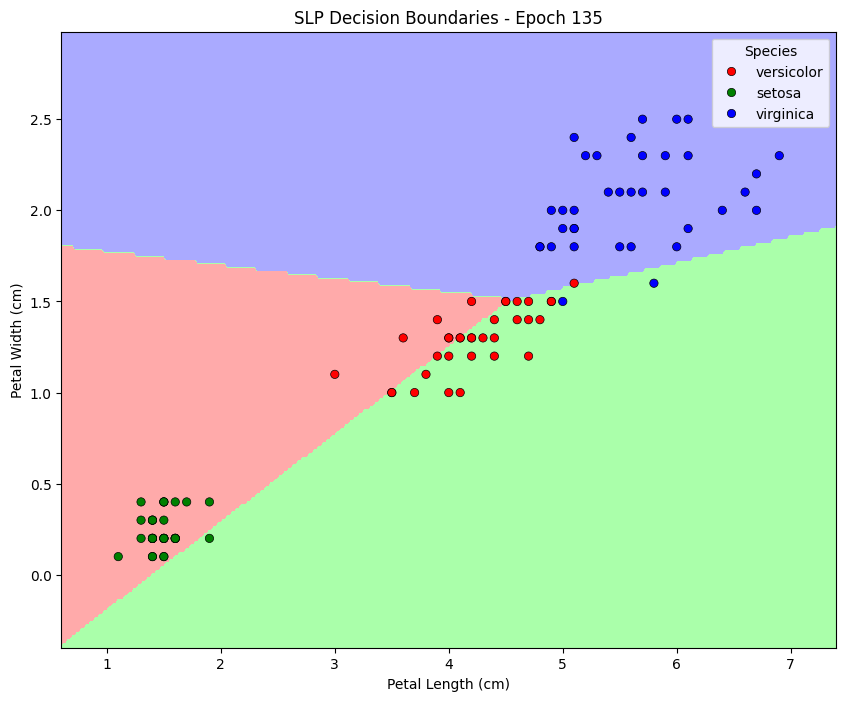

--- Epoch 140 ---


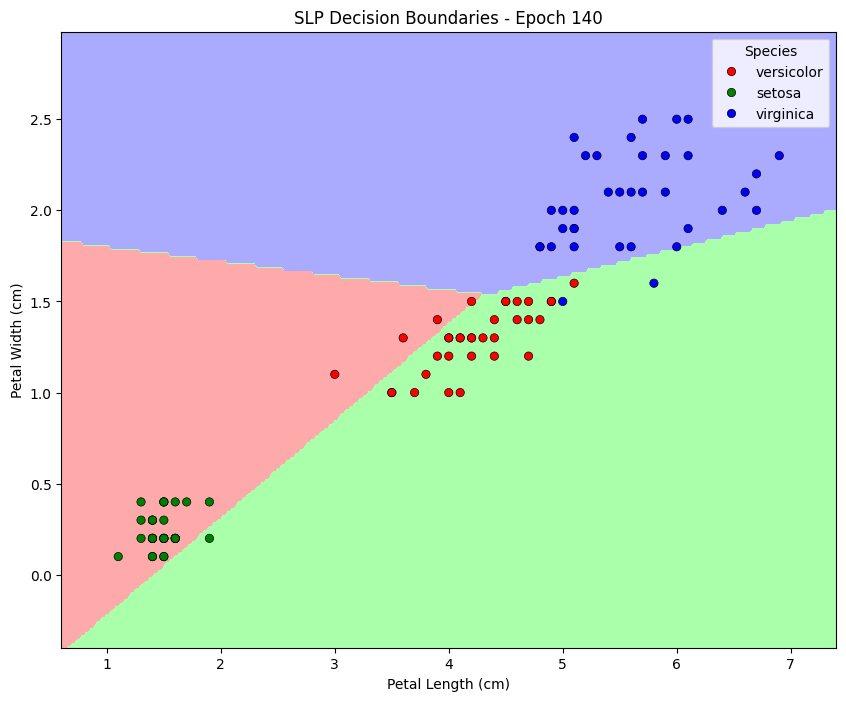

--- Epoch 145 ---


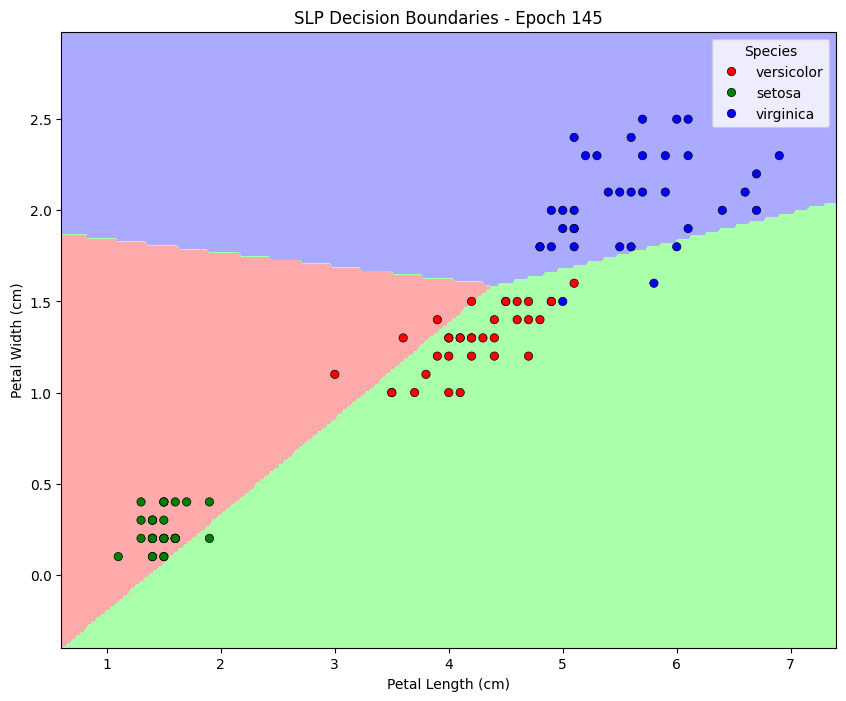

--- Epoch 150 ---


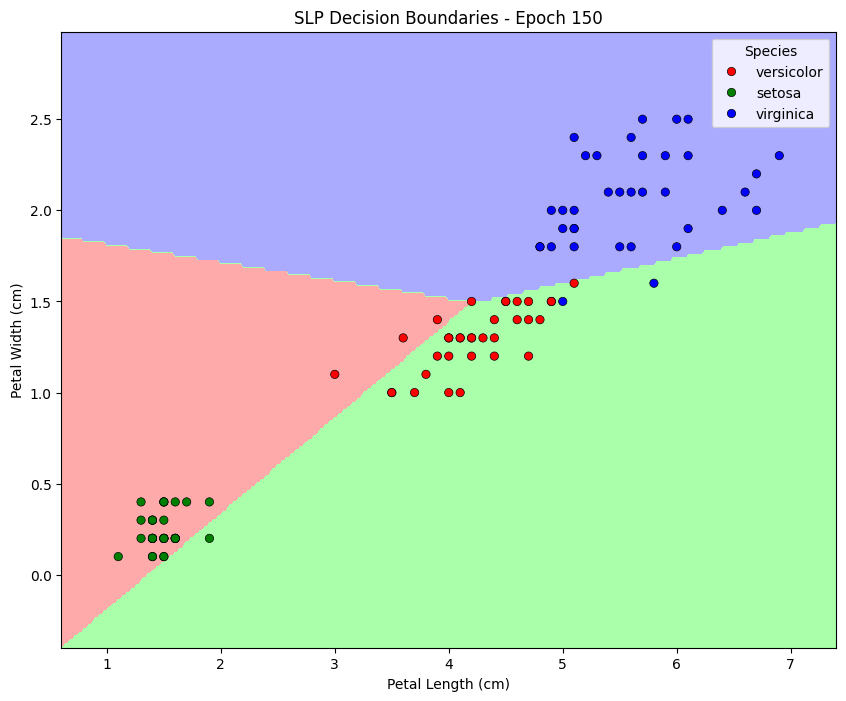

In [87]:
n_classes = len(np.unique(y_full))

# Create OvR model
slp_ovr_model = SLP_OvR(n_classes=n_classes, learning_rate=0.1, n_iters=150, random_state=42)

# Train the model
slp_ovr_model.fit(X_train_2f, y_train, plot_every=5)

In [88]:
y_pred = slp_ovr_model.predict(X_test_2f)

In [89]:
# evaluate results
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Test Accuracy: {accuracy:.2f}")
print("\nClassification Report:")
report = classification_report(y_test, y_pred)
display(Markdown(f"```\n{report}\n```")) # [cite: 22]
print("\nConfusion Matrix:") # [cite: 22]
print(confusion_matrix(y_test, y_pred))


Model Test Accuracy: 0.89

Classification Report:


```
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        15
           1       0.86      0.80      0.83        15
           2       0.81      0.87      0.84        15

    accuracy                           0.89        45
   macro avg       0.89      0.89      0.89        45
weighted avg       0.89      0.89      0.89        45

```


Confusion Matrix:
[[15  0  0]
 [ 0 12  3]
 [ 0  2 13]]


In [90]:


class MLPClassifierFromScratch:
    """
    Single Hidden Layer Multi-Layer Perceptron (MLP) Classifier from scratch using NumPy.
    1 hidden layer with tanh activation and softmax output layer.
    Uses Stochastic Gradient Descent (SGD) and backpropagation for training.
    """
    def __init__(self, n_hidden=10, learning_rate=0.01, n_iters=100, random_state=42):
        self.n_hidden = n_hidden          # Neurons in hidden layer
        self.lr = learning_rate         # Learning rate
        self.n_iters = n_iters            # Number of epochs
        self.random_state = random_state  # For reproducibility
        self.weights1 = None              # Input -> Hidden layer weights
        self.bias1 = None                 # Hidden layer bias
        self.weights2 = None              # Hidden layer -> Output weights
        self.bias2 = None                 # Output layer bias

    def _tanh(self, x):
        return np.tanh(x)

    def _tanh_derivative(self, x):
        return 1 - np.tanh(x)**2

    def _softmax(self, z):
        # For numerical stability, we subtract the max value from z.
        exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def fit(self, X, y):
        """Train the model."""
        n_samples, n_features = X.shape
        n_outputs = len(np.unique(y))

        # Initialize weights and biases randomly
        np.random.seed(self.random_state)
        self.weights1 = np.random.randn(n_features, self.n_hidden) * 0.01
        self.bias1 = np.zeros((1, self.n_hidden))
        self.weights2 = np.random.randn(self.n_hidden, n_outputs) * 0.01
        self.bias2 = np.zeros((1, n_outputs))

        # One-hot encoding for y
        y_one_hot = np.zeros((n_samples, n_outputs))
        y_one_hot[np.arange(n_samples), y] = 1

        # SGD Training Loop
        for epoch in range(self.n_iters):
            # Shuffle the data at each epoch (Stochastic property)
            indices = np.random.permutation(n_samples)
            X_shuffled = X[indices]
            y_shuffled_one_hot = y_one_hot[indices]

            for i in range(n_samples):
                xi = X_shuffled[i:i+1]
                yi = y_shuffled_one_hot[i:i+1]

                # 1. Forward Propagation
                # Input -> Hidden Layer
                z1 = np.dot(xi, self.weights1) + self.bias1
                a1 = self._tanh(z1)

                # Hidden -> Output Layer
                z2 = np.dot(a1, self.weights2) + self.bias2
                y_pred_proba = self._softmax(z2)

                # 2. Backpropagation
                # Output layer error
                delta2 = y_pred_proba - yi

                # Hidden layer error
                d_z1 = self._tanh_derivative(z1)
                delta1 = np.dot(delta2, self.weights2.T) * d_z1

                # 3. Weight and Bias Updates
                # Hidden -> Output weights
                self.weights2 -= self.lr * np.dot(a1.T, delta2)
                self.bias2 -= self.lr * np.sum(delta2, axis=0, keepdims=True)

                # Input -> Hidden weights
                self.weights1 -= self.lr * np.dot(xi.T, delta1)
                self.bias1 -= self.lr * np.sum(delta1, axis=0, keepdims=True)

    def predict_proba(self, X):
        """Predict class probabilities."""
        z1 = np.dot(X, self.weights1) + self.bias1
        a1 = self._tanh(z1)
        z2 = np.dot(a1, self.weights2) + self.bias2
        return self._softmax(z2)

    def predict(self, X):
        """Predict class labels."""
        probas = self.predict_proba(X)
        return np.argmax(probas, axis=1)

--- 'FROM SCRATCH' MLP TEST REPORT ---


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

```


Confusion Matrix:


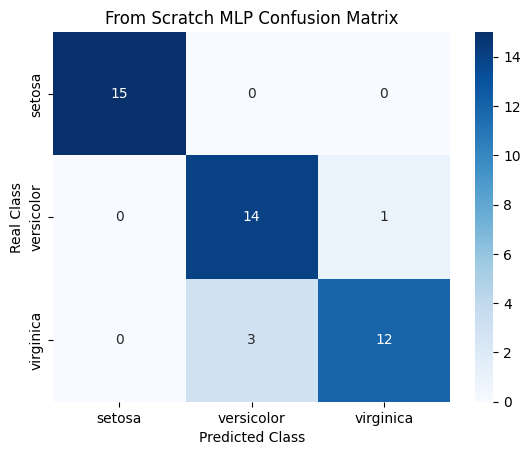

In [91]:
# This Hyperparameter settings are good for a start, you can experiment more in the bonus part.
mlp_scratch = MLPClassifierFromScratch(n_hidden=10, learning_rate=0.01, n_iters=150, random_state=42)

# Train the model with 2-feature training data
# (We use 2 features to be able to draw decision boundaries)
mlp_scratch.fit(X_train_2f_scaled, y_train)

# Make predictions on the test set
y_pred_mlp_scratch = mlp_scratch.predict(X_test_2f_scaled)

# --- EVALUATION ---

print("--- 'FROM SCRATCH' MLP TEST REPORT ---")
report = classification_report(y_test, y_pred_mlp_scratch, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred_mlp_scratch)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted Class')
plt.ylabel('Real Class')
plt.title('From Scratch MLP Confusion Matrix')
plt.show()

Decision Boundaries:


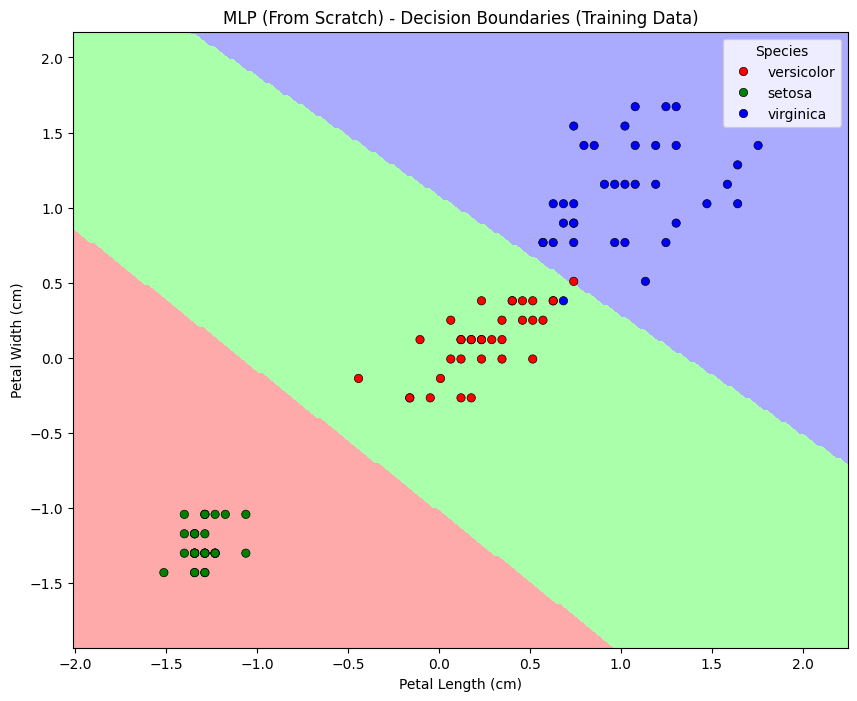

/tmp/ipykernel_4106/2137855523.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


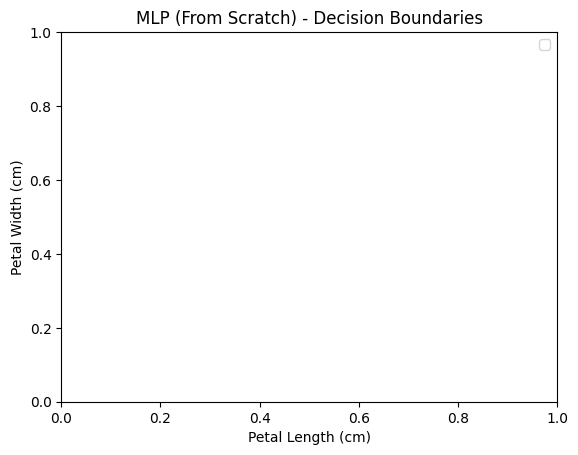

In [92]:

print("Decision Boundaries:")
plot_decision_boundary(X_train_2f_scaled, y_train, mlp_scratch, title="MLP (From Scratch) - Decision Boundaries (Training Data)")
plt.title("MLP (From Scratch) - Decision Boundaries")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.legend()
plt.show()

In [93]:
print(f"X train shape that use in Part 3: {X_train_full.shape}")
print(f"X train shape that use in Part 3: {y_train.shape}")

X train shape that use in Part 3: (105, 4)
X train shape that use in Part 3: (105,)


--- Part 3: Scikit-learn Perceptron Model ---
Fitting 5 folds for each of 9 candidates, totalling 45 fits

--- Perceptron results ---
Best parameters:  {'classifier__eta0': 0.1, 'selector__k': 4}
Selected best features (4): ['sepal length (cm)' 'sepal width (cm)' 'petal length (cm)'
 'petal width (cm)']

Test Report:


```
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.65      0.87      0.74        15
   virginica       1.00      0.53      0.70        15

    accuracy                           0.80        45
   macro avg       0.84      0.80      0.79        45
weighted avg       0.84      0.80      0.79        45

```

Confusion Matrix:


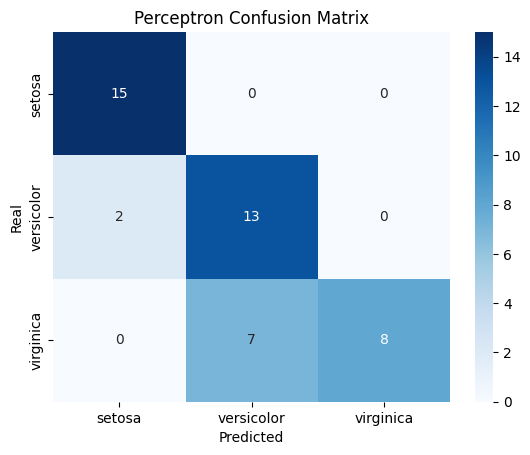

In [94]:
# --- PART 3 ---

print("--- Part 3: Scikit-learn Perceptron Model ---")

# Pipeline ve GridSearchCV
pipe_perceptron = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('classifier', Perceptron(random_state=42, max_iter=2000))
])
param_grid_perceptron = {
    'selector__k': [2, 3, 4],
    'classifier__eta0': [0.001, 0.01, 0.1]
}
grid_search_perceptron = GridSearchCV(pipe_perceptron, param_grid_perceptron, cv=5, verbose=1, n_jobs=-1)
grid_search_perceptron.fit(X_train_full, y_train)

# Take the best model from grid search
best_perceptron = grid_search_perceptron.best_estimator_

# --- Feature Selection ---
# Accessing the 'selector' step of the best model
selector = best_perceptron.named_steps['selector']
# Getting the indices of the selected features
selected_indices = selector.get_support(indices=True)
# Getting the feature names corresponding to these indices
feature_names = np.array(iris.feature_names)
selected_features = feature_names[selected_indices]

print("\n--- Perceptron results ---")
print("Best parameters: ", grid_search_perceptron.best_params_)
print(f"Selected best features ({len(selected_features)}): {selected_features}")

# Test performance (classification_report and confusion_matrix)
y_pred_perceptron_lib = best_perceptron.predict(X_test_full)
print("\nTest Report:")
report = classification_report(y_test, y_pred_perceptron_lib, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred_perceptron_lib)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('Perceptron Confusion Matrix')
plt.show()



--- Part 3: Scikit-learn MLPClassifier Model ---
Fitting 5 folds for each of 36 candidates, totalling 180 fits

--- MLPClassifier Results ---
Best parameters:  {'classifier__activation': 'relu', 'classifier__hidden_layer_sizes': (20,), 'classifier__learning_rate_init': 0.01, 'selector__k': 4}
Selected best features (4): ['sepal length (cm)' 'sepal width (cm)' 'petal length (cm)'
 'petal width (cm)']

Test Report:


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45

```

Confusion Matrix:


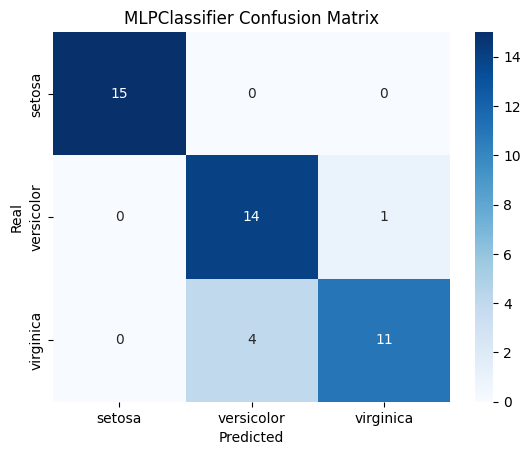

In [95]:
print("\n\n--- Part 3: Scikit-learn MLPClassifier Model ---")

# Pipeline (solver='sgd' added)
pipe_mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(f_classif)),
    ('classifier', MLPClassifier(random_state=42, max_iter=2000, early_stopping=True, solver='sgd')) # <-- This Change for MLPClassifier
])

# GridSearchCV
param_grid_mlp = {
    'selector__k': [2, 3, 4],
    'classifier__hidden_layer_sizes': [(10,), (20,), (10, 5)],
    'classifier__activation': ['tanh', 'relu'],
    'classifier__learning_rate_init': [0.001, 0.01]
}
grid_search_mlp = GridSearchCV(pipe_mlp, param_grid_mlp, cv=5, verbose=1, n_jobs=-1)
grid_search_mlp.fit(X_train_full, y_train)

# En iyi modeli al
best_mlp = grid_search_mlp.best_estimator_

# --- Feature Selection ---
selector_mlp = best_mlp.named_steps['selector']
selected_indices_mlp = selector_mlp.get_support(indices=True)
selected_features_mlp = feature_names[selected_indices_mlp]

print("\n--- MLPClassifier Results ---")
print("Best parameters: ", grid_search_mlp.best_params_)
print(f"Selected best features ({len(selected_features_mlp)}): {selected_features_mlp}")

# Test performance (classification_report and confusion_matrix)
y_pred_mlp_lib = best_mlp.predict(X_test_full)
print("\nTest Report:")
report = classification_report(y_test, y_pred_mlp_lib, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))

print("Confusion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred_mlp_lib)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Real')
plt.title('MLPClassifier Confusion Matrix')
plt.show()

In [96]:
# ----------------------------------------------------------------------
# Scikit models test evaluation
# ----------------------------------------------------------------------

print("="*50)
print("Scikit-learn Models Test Evaluation")
print("="*50)

# 1. take the best SLP (Perceptron) model and predict on X_test
# grid_search_perceptron variable is assumed to be trained in the previous cell
best_slp_model = grid_search_perceptron.best_estimator_
y_pred_slp_sklearn = best_slp_model.predict(X_test_full) # Original X_test (4 features)

print("\n--- 1. SKLEARN PERCEPTRON (BEST MODEL) TEST REPORT ---")
print(f"Best parameters: {grid_search_perceptron.best_params_}")
report = classification_report(y_test, y_pred_slp_sklearn, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_slp = confusion_matrix(y_test, y_pred_slp_sklearn)
print(cm_slp)

# 2. take the best MLP (MLPClassifier) model and predict on X_test
# grid_search_mlp variable is assumed to be trained in the previous cell
best_mlp_model_sklearn = grid_search_mlp.best_estimator_
y_pred_mlp_sklearn = best_mlp_model_sklearn.predict(X_test_full) # Original X_test (4 features)

print("\n--- 2. SKLEARN MLPCLASSIFIER (BEST MODEL) TEST REPORT ---")
print(f"Best parameters: {grid_search_mlp.best_params_}")
report = classification_report(y_test, y_pred_mlp_sklearn, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred_mlp_sklearn)
print(cm_mlp)

Scikit-learn Models Test Evaluation

--- 1. SKLEARN PERCEPTRON (BEST MODEL) TEST REPORT ---
Best parameters: {'classifier__eta0': 0.1, 'selector__k': 4}


```
              precision    recall  f1-score   support

      setosa       0.88      1.00      0.94        15
  versicolor       0.65      0.87      0.74        15
   virginica       1.00      0.53      0.70        15

    accuracy                           0.80        45
   macro avg       0.84      0.80      0.79        45
weighted avg       0.84      0.80      0.79        45

```

Confusion Matrix:
[[15  0  0]
 [ 2 13  0]
 [ 0  7  8]]

--- 2. SKLEARN MLPCLASSIFIER (BEST MODEL) TEST REPORT ---
Best parameters: {'classifier__activation': 'relu', 'classifier__hidden_layer_sizes': (20,), 'classifier__learning_rate_init': 0.01, 'selector__k': 4}


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.78      0.93      0.85        15
   virginica       0.92      0.73      0.81        15

    accuracy                           0.89        45
   macro avg       0.90      0.89      0.89        45
weighted avg       0.90      0.89      0.89        45

```

Confusion Matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  4 11]]


In [97]:
# ----------------------------------------------------------------------
# Scratch models test evaluation
# ----------------------------------------------------------------------

print("\n" + "="*50)
print("PART 2 - 'FROM-SCRATCH' MODELS TEST EVALUATION")
print("="*50)

# Scratch modells trained with 2 features (X_train_2f),
# So we will evaluate them on X_test_2f
# y_test remains the original 1D labels.

# 1. Scratch SLP model evaluation
# 'slp_ovr' models trained in Part 2 with 2 features
y_pred_slp_scratch = slp_ovr_model.predict(X_test_2f)

print("\n--- 1. 'FROM-SCRATCH' SLP (SLP_OvR) TEST REPORT ---")
report = classification_report(y_test, y_pred_slp_scratch, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_slp_scratch = confusion_matrix(y_test, y_pred_slp_scratch)
print(cm_slp_scratch)


# 2. Scratch MLP model evaluation
# 'mlp_ovr' model trained in Part 2 with 2 features
#
# -----------------------------------------------------------------
# 
# predict method of 'MLP_OvR' returns (n_samples, n_classes) shape,
# while 'MLPClassifierFromScratch' returns (n_samples,) shape.
# So we need to handle both cases here.


try:
    # if you have trained 'MLP_OvR' (Cell 11) model and named it 'mlp_ovr':
    y_pred_mlp_scratch = mlp_scratch.predict(X_test_2f_scaled)
    
except AttributeError:
    # if you have trained 'MLPClassifierFromScratch' (Cell 10)
    # and named it differently, change the variable name below:
    # y_pred_mlp_scratch = best_mlp_model.predict(X_test_2f)
    print("Error: 'MLP_OvR' model not found.")
    print("Please enter the variable name of your trained model (e.g., 'best_mlp_model').")
    y_pred_mlp_scratch = y_pred_slp_scratch # Temporarily suppress the error


# 'MLP_OvR' (Cell 11) model returns (n_samples, n_classes) shape,
# 'MLPClassifierFromScratch' = (112,) . To be Sure, we check the shape here:
if y_pred_mlp_scratch.ndim > 1:
    y_pred_mlp_scratch = np.argmax(y_pred_mlp_scratch, axis=1)
    



print("\n--- 2. 'SIFIRDAN' MLP (MLP_OvR / MLPClassifierFromScratch) TEST REPORT ---")
report = classification_report(y_test, y_pred_mlp_scratch, target_names=iris.target_names)
display(Markdown(f"```\n{report}\n```"))
print("Confusion Matrix:")
cm_mlp_scratch = confusion_matrix(y_test, y_pred_mlp_scratch)
print(cm_mlp_scratch)




PART 2 - 'FROM-SCRATCH' MODELS TEST EVALUATION

--- 1. 'FROM-SCRATCH' SLP (SLP_OvR) TEST REPORT ---


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.86      0.80      0.83        15
   virginica       0.81      0.87      0.84        15

    accuracy                           0.89        45
   macro avg       0.89      0.89      0.89        45
weighted avg       0.89      0.89      0.89        45

```

Confusion Matrix:
[[15  0  0]
 [ 0 12  3]
 [ 0  2 13]]

--- 2. 'SIFIRDAN' MLP (MLP_OvR / MLPClassifierFromScratch) TEST REPORT ---


```
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

```

Confusion Matrix:
[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]
